In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix,precision_score,recall_score,f1_score
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"D:\Imarticus\ML\E-commerce_return_abuse_detection_dataset\ecommerce_return_abuse_dataset.csv")
df

,order_id,customer_id,age,account_age_days,customer_segment,country,platform,device_type,payment_method,product_category,...,shipping_carrier,address_change_before_delivery,refund_to_different_account,multiple_accounts_flag,customer_support_contacts,previous_dispute_count,wishlist_to_cart_time_hrs,review_left_after_return,abuse_type,abuse_label
0,ORD2024554,CUST408891,68,1473,New,US,Web Browser,iPhone,Crypto,Toys,...,OnTrac,0,0,0,1,0,70.5,0,Legitimate,0
1,ORD2019797,CUST898762,64,1211,Silver,FR,Tablet App,MacBook,PayPal,Books,...,FedEx,0,0,0,0,0,25.3,0,Legitimate,0
2,ORD2058733,CUST906263,52,1291,Bronze,US,Web Browser,iPad,Crypto,Clothing,...,FedEx,1,0,0,0,0,36.6,0,Legitimate,0
3,ORD2015301,CUST601672,63,1743,Bronze,CA,Web Browser,iPhone,PayPal,Home & Kitchen,...,USPS,1,0,0,3,0,4.4,1,Fraudulent Return,2
4,ORD2014206,CUST316429,21,2478,Gold,US,Web Browser,Windows PC,Debit Card,Clothing,...,OnTrac,0,0,0,1,1,40.9,0,Legitimate,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,ORD2040621,CUST446435,42,2378,Bronze,CA,Web Browser,Windows PC,Crypto,Clothing,...,FedEx,0,0,1,5,1,3.8,0,Fraudulent Return,2
59996,ORD2007646,CUST594586,36,2483,Bronze,DE,Tablet App,iPad,Gift Card,Toys,...,DHL,0,0,0,1,1,36.8,0,Legitimate,0
59997,ORD2029730,CUST793088,39,1775,Silver,GB,Tablet App,iPhone,Debit Card,Clothing,...,DHL,0,0,0,1,0,3.3,0,Legitimate,0
59998,ORD2044308,CUST317152,53,1637,Silver,US,Web Browser,MacBook,Buy Now Pay Later,Electronics,...,UPS,0,0,0,1,5,42.5,0,Policy Abuser,1


In [3]:
df.shape

(60000, 35)

In [4]:
df.head()

,order_id,customer_id,age,account_age_days,customer_segment,country,platform,device_type,payment_method,product_category,...,shipping_carrier,address_change_before_delivery,refund_to_different_account,multiple_accounts_flag,customer_support_contacts,previous_dispute_count,wishlist_to_cart_time_hrs,review_left_after_return,abuse_type,abuse_label
0,ORD2024554,CUST408891,68,1473,New,US,Web Browser,iPhone,Crypto,Toys,...,OnTrac,0,0,0,1,0,70.5,0,Legitimate,0
1,ORD2019797,CUST898762,64,1211,Silver,FR,Tablet App,MacBook,PayPal,Books,...,FedEx,0,0,0,0,0,25.3,0,Legitimate,0
2,ORD2058733,CUST906263,52,1291,Bronze,US,Web Browser,iPad,Crypto,Clothing,...,FedEx,1,0,0,0,0,36.6,0,Legitimate,0
3,ORD2015301,CUST601672,63,1743,Bronze,CA,Web Browser,iPhone,PayPal,Home & Kitchen,...,USPS,1,0,0,3,0,4.4,1,Fraudulent Return,2
4,ORD2014206,CUST316429,21,2478,Gold,US,Web Browser,Windows PC,Debit Card,Clothing,...,OnTrac,0,0,0,1,1,40.9,0,Legitimate,0


In [5]:
df.tail()

,order_id,customer_id,age,account_age_days,customer_segment,country,platform,device_type,payment_method,product_category,...,shipping_carrier,address_change_before_delivery,refund_to_different_account,multiple_accounts_flag,customer_support_contacts,previous_dispute_count,wishlist_to_cart_time_hrs,review_left_after_return,abuse_type,abuse_label
59995,ORD2040621,CUST446435,42,2378,Bronze,CA,Web Browser,Windows PC,Crypto,Clothing,...,FedEx,0,0,1,5,1,3.8,0,Fraudulent Return,2
59996,ORD2007646,CUST594586,36,2483,Bronze,DE,Tablet App,iPad,Gift Card,Toys,...,DHL,0,0,0,1,1,36.8,0,Legitimate,0
59997,ORD2029730,CUST793088,39,1775,Silver,GB,Tablet App,iPhone,Debit Card,Clothing,...,DHL,0,0,0,1,0,3.3,0,Legitimate,0
59998,ORD2044308,CUST317152,53,1637,Silver,US,Web Browser,MacBook,Buy Now Pay Later,Electronics,...,UPS,0,0,0,1,5,42.5,0,Policy Abuser,1
59999,ORD2009126,CUST754487,52,936,Bronze,DE,Tablet App,Android,Buy Now Pay Later,Jewelry,...,OnTrac,0,0,0,6,4,3.9,0,Fraudulent Return,2


In [6]:
df.sample()

,order_id,customer_id,age,account_age_days,customer_segment,country,platform,device_type,payment_method,product_category,...,shipping_carrier,address_change_before_delivery,refund_to_different_account,multiple_accounts_flag,customer_support_contacts,previous_dispute_count,wishlist_to_cart_time_hrs,review_left_after_return,abuse_type,abuse_label
53949,ORD2008814,CUST768074,44,575,Gold,FR,Mobile App,iPhone,PayPal,Beauty,...,OnTrac,0,0,0,3,0,2.3,0,Wardrobing,3


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   order_id                        60000 non-null  object 
 1   customer_id                     60000 non-null  object 
 2   age                             60000 non-null  int64  
 3   account_age_days                60000 non-null  int64  
 4   customer_segment                60000 non-null  object 
 5   country                         60000 non-null  object 
 6   platform                        60000 non-null  object 
 7   device_type                     60000 non-null  object 
 8   payment_method                  60000 non-null  object 
 9   product_category                60000 non-null  object 
 10  avg_order_value_usd             60000 non-null  float64
 11  refund_amount_requested_usd     60000 non-null  float64
 12  is_high_value_item              

In [8]:
df.describe()

,age,account_age_days,avg_order_value_usd,refund_amount_requested_usd,is_high_value_item,discount_used,days_to_return,total_orders_lifetime,total_returns_lifetime,return_rate_pct,...,photo_evidence_provided,tracking_number_valid,address_change_before_delivery,refund_to_different_account,multiple_accounts_flag,customer_support_contacts,previous_dispute_count,wishlist_to_cart_time_hrs,review_left_after_return,abuse_label
count,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,...,60000.000000,60000.00000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.000000,60000.00000
mean,44.105383,1250.687700,188.987098,176.197371,0.379300,0.238650,16.087550,41.304550,8.943850,19.073007,...,0.379417,0.92850,0.093450,0.040867,0.078350,1.392000,1.098050,30.168445,0.249917,0.55540
std,15.258403,722.018931,137.797571,136.587287,0.485217,0.426262,11.395042,25.198816,15.000508,22.730017,...,0.485246,0.25766,0.291064,0.197983,0.268724,1.705995,1.375367,22.863372,0.432968,0.95618
min,18.000000,1.000000,15.000000,12.120000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.000000,0.00000
25%,31.000000,626.000000,92.850000,84.410000,0.000000,0.000000,6.000000,20.000000,1.000000,2.700000,...,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,6.200000,0.000000,0.00000
50%,44.000000,1251.000000,165.115000,150.510000,0.000000,0.000000,15.000000,39.000000,3.000000,8.800000,...,0.000000,1.00000,0.000000,0.000000,0.000000,1.000000,1.000000,28.400000,0.000000,0.00000
75%,57.000000,1875.000000,247.672500,224.025000,1.000000,0.000000,24.000000,60.000000,9.000000,35.500000,...,1.000000,1.00000,0.000000,0.000000,0.000000,1.000000,1.000000,50.400000,0.000000,1.00000
max,70.000000,2500.000000,799.960000,836.680000,1.000000,1.000000,55.000000,120.000000,101.000000,84.700000,...,1.000000,1.00000,1.000000,1.000000,1.000000,6.000000,5.000000,72.000000,1.000000,3.00000


In [9]:
df.columns

Index(['order_id', 'customer_id', 'age', 'account_age_days',
       'customer_segment', 'country', 'platform', 'device_type',
       'payment_method', 'product_category', 'avg_order_value_usd',
       'refund_amount_requested_usd', 'is_high_value_item', 'discount_used',
       'order_date', 'return_date', 'days_to_return', 'return_reason',
       'total_orders_lifetime', 'total_returns_lifetime', 'return_rate_pct',
       'item_returned_opened', 'return_packaging_intact',
       'photo_evidence_provided', 'tracking_number_valid', 'shipping_carrier',
       'address_change_before_delivery', 'refund_to_different_account',
       'multiple_accounts_flag', 'customer_support_contacts',
       'previous_dispute_count', 'wishlist_to_cart_time_hrs',
       'review_left_after_return', 'abuse_type', 'abuse_label'],
      dtype='object')

In [10]:
df.isnull().sum()

order_id                          0
customer_id                       0
age                               0
account_age_days                  0
customer_segment                  0
country                           0
platform                          0
device_type                       0
payment_method                    0
product_category                  0
avg_order_value_usd               0
refund_amount_requested_usd       0
is_high_value_item                0
discount_used                     0
order_date                        0
return_date                       0
days_to_return                    0
return_reason                     0
total_orders_lifetime             0
total_returns_lifetime            0
return_rate_pct                   0
item_returned_opened              0
return_packaging_intact           0
photo_evidence_provided           0
tracking_number_valid             0
shipping_carrier                  0
address_change_before_delivery    0
refund_to_different_account 

In [11]:
df.duplicated().sum()

np.int64(0)

### 1. Distribution of Return Abuse Types
Purpose: Understand how many returns are legitimate versus suspicious.

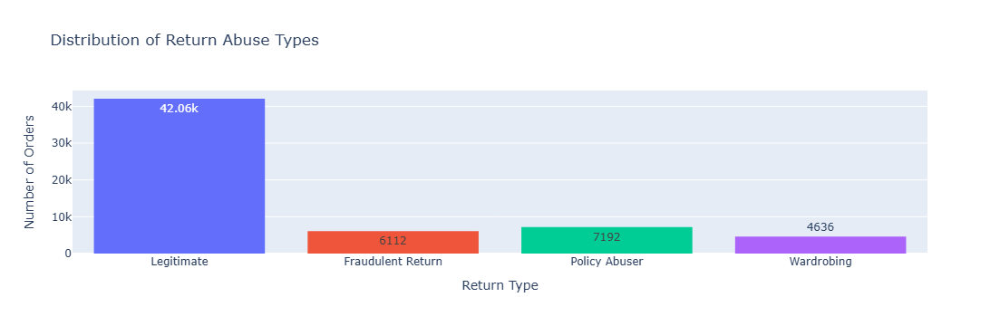

In [12]:
fig = px.histogram(
    df,
    x="abuse_type",
    color="abuse_type",
    title="Distribution of Return Abuse Types",
    labels={"abuse_type": "Return Type"},
    text_auto=True
)

fig.update_layout(
    xaxis_title="Return Type",
    yaxis_title="Number of Orders",
    showlegend=False
)

fig.show()

### 2. Requested Refund Amount by Abuse Type
Purpose: Compare the financial exposure associated with different return types.

In [13]:
fig = px.box(
    df,
    x="abuse_type",
    y="refund_amount_requested_usd",
    color="abuse_type",
    title="Refund Amount Distribution by Abuse Type",
    labels={
        "abuse_type": "Return Type",
        "refund_amount_requested_usd": "Requested Refund (USD)"
    }
)

fig.update_layout(showlegend=False)
fig.show()

### 3. Customer Return Rate vs Requested Refund
Purpose: Examine whether customers with higher return rates also request larger refunds.

In [14]:
fig = px.scatter(
    df,
    x="return_rate_pct",
    y="refund_amount_requested_usd",
    color="abuse_type",
    hover_data=["order_id", "customer_id"],
    title="Customer Return Rate vs Requested Refund",
    labels={
        "return_rate_pct": "Customer Return Rate (%)",
        "refund_amount_requested_usd": "Requested Refund (USD)",
        "abuse_type": "Return Type"
    },
    opacity=0.7
)

fig.show()

### 4. Return Reasons by Abuse Type
Purpose: Identify the return reasons most commonly associated with each category.

In [15]:
fig = px.histogram(
    df,
    x="return_reason",
    color="abuse_type",
    barmode="group",
    title="Return Reasons by Abuse Type",
    labels={
        "return_reason": "Return Reason",
        "count": "Number of Orders",
        "abuse_type": "Return Type"
    }
)

fig.update_layout(
    xaxis_title="Return Reason",
    yaxis_title="Number of Orders",
    xaxis_tickangle=-35
)

fig.show()

### 5. Return Delay vs Abuse Type
Purpose: Explore whether the time taken to return an item differs across return types.

In [16]:
fig = px.violin(
    df,
    x="abuse_type",
    y="days_to_return",
    color="abuse_type",
    box=True,
    points="outliers",
    title="Return Delay Distribution by Abuse Type",
    labels={
        "abuse_type": "Return Type",
        "days_to_return": "Days Until Return"
    }
)

fig.update_layout(showlegend=False)
fig.show()

In [17]:
numeric = df.select_dtypes(include = 'number')
for col in numeric:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outliers = outliers.shape[0]
    print(f"{col}:{outliers}")

age:0
account_age_days:0
avg_order_value_usd:2868
refund_amount_requested_usd:3492
is_high_value_item:0
discount_used:14319
days_to_return:615
total_orders_lifetime:0
total_returns_lifetime:7061
return_rate_pct:1
item_returned_opened:0
return_packaging_intact:0
photo_evidence_provided:0
tracking_number_valid:4290
address_change_before_delivery:5607
refund_to_different_account:2452
multiple_accounts_flag:4701
customer_support_contacts:11916
previous_dispute_count:9017
wishlist_to_cart_time_hrs:0
review_left_after_return:14995
abuse_label:4636


In [18]:
df["abuse_label"].value_counts()

abuse_label
0    42060
1     7192
2     6112
3     4636
Name: count, dtype: int64

In [19]:
x = df.drop('abuse_label',axis=1)
y = df[['abuse_label']]

In [20]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state = 42)

In [21]:
print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (60000, 34)
y shape: (60000, 1)


In [22]:
numerical_cols = x_train.select_dtypes(include= ["int64", "float64"]).columns
categorical_cols = x_train.select_dtypes(include=["object", "category", "bool"]).columns
print("numerical columns:", list(numerical_cols))
print("\nCategorical columns:", list(categorical_cols))

numerical columns: ['age', 'account_age_days', 'avg_order_value_usd', 'refund_amount_requested_usd', 'is_high_value_item', 'discount_used', 'days_to_return', 'total_orders_lifetime', 'total_returns_lifetime', 'return_rate_pct', 'item_returned_opened', 'return_packaging_intact', 'photo_evidence_provided', 'tracking_number_valid', 'address_change_before_delivery', 'refund_to_different_account', 'multiple_accounts_flag', 'customer_support_contacts', 'previous_dispute_count', 'wishlist_to_cart_time_hrs', 'review_left_after_return']

Categorical columns: ['order_id', 'customer_id', 'customer_segment', 'country', 'platform', 'device_type', 'payment_method', 'product_category', 'order_date', 'return_date', 'return_reason', 'shipping_carrier', 'abuse_type']


In [23]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(x_train)
X_test_processed = preprocessor.transform(x_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (48000, 96255)
Processed testing shape: (12000, 96255)


In [24]:
lr_model = LogisticRegression()

In [25]:
lr_model.fit(X_train_processed,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [26]:
y_pred = lr_model.predict(X_test_processed)

In [27]:
print("Accuracy Score",accuracy_score(y_pred,y_test))

Accuracy Score 0.99575


In [28]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8519
           1       0.99      0.98      0.98      1386
           2       0.99      0.99      0.99      1166
           3       0.98      0.99      0.98       929

    accuracy                           1.00     12000
   macro avg       0.99      0.99      0.99     12000
weighted avg       1.00      1.00      1.00     12000



In [29]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[8513    0    0    6]
 [   1 1358   12   15]
 [   1    7 1158    0]
 [   1    8    0  920]]


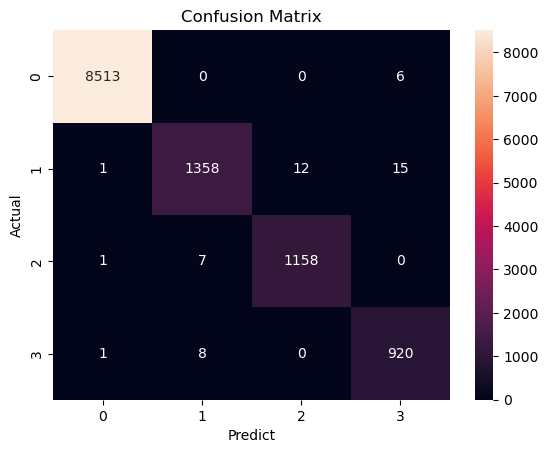

In [30]:
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm , annot = True , fmt = 'd')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [31]:
print("Training Accuracy",lr_model.score(X_train_processed,y_train))
print("Testing Accuracy",lr_model.score(X_test_processed,y_test))

Training Accuracy 0.9958958333333333
Testing Accuracy 0.99575


In [32]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [33]:
rf_model.fit(X_train_processed,y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
y_pred_rf = rf_model.predict(X_test_processed)

In [35]:
print("Accuracy Score",accuracy_score(y_test, y_pred_rf))

Accuracy Score 1.0


In [36]:
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf, zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8519
           1       1.00      1.00      1.00      1386
           2       1.00      1.00      1.00      1166
           3       1.00      1.00      1.00       929

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000



In [37]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Confusion Matrix:
[[8519    0    0    0]
 [   0 1386    0    0]
 [   0    0 1166    0]
 [   0    0    0  929]]


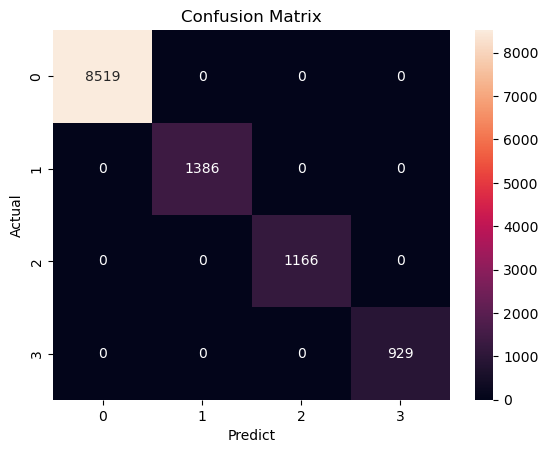

In [38]:
cm = confusion_matrix(y_test,y_pred_rf)
sns.heatmap(cm , annot = True , fmt = 'd')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [39]:
print("Training Accuracy",rf_model.score(X_train_processed,y_train))
print("Testing Accuracy",rf_model.score(X_test_processed,y_test))

Training Accuracy 1.0
Testing Accuracy 1.0


In [40]:
print(type(y))
print(y.shape)
print(y.head())
print(y.columns)

<class 'pandas.core.frame.DataFrame'>
(60000, 1)
   abuse_label
0            0
1            0
2            0
3            2
4            0
Index(['abuse_label'], dtype='object')


In [41]:
y = df["abuse_label"].squeeze()

print("Target classes:", sorted(y.unique()))
print(y.value_counts())

Target classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
abuse_label
0    42060
1     7192
2     6112
3     4636
Name: count, dtype: int64


In [42]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        precision_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)
    ]
})

print(comparison.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.996      0.996   0.996     0.996
1        Random Forest     1.000      1.000   1.000     1.000


In [43]:
# %pip install xgboost

In [44]:
xgb_model = XGBClassifier()

In [45]:
xgb_model.fit(X_train_processed,y_train)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [46]:
y_pred_xgb = xgb_model.predict(X_test_processed)

In [47]:
print("XGBoost Accuracy:",accuracy_score(y_test, y_pred_xgb))

XGBoost Accuracy: 1.0


In [48]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_xgb,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8519
           1       1.00      1.00      1.00      1386
           2       1.00      1.00      1.00      1166
           3       1.00      1.00      1.00       929

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000


Confusion Matrix:
[[8519    0    0    0]
 [   0 1386    0    0]
 [   0    0 1166    0]
 [   0    0    0  929]]


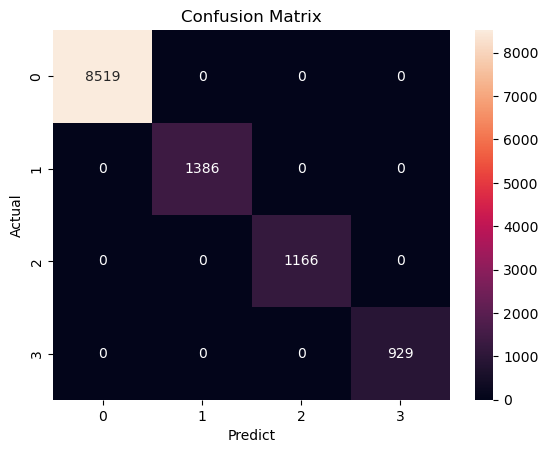

In [49]:
cm = confusion_matrix(y_test,y_pred_xgb)
sns.heatmap(cm , annot = True , fmt = 'd')
plt.xlabel('Predict')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

models = {
    "Logistic Regression": y_pred,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions,
            average="weighted", zero_division=0
        )
    })

comparison = pd.DataFrame(results)
print(comparison.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.996      0.996   0.996     0.996
1        Random Forest     1.000      1.000   1.000     1.000
2              XGBoost     1.000      1.000   1.000     1.000


In [51]:
# 1. Check target distribution
print("Target distribution:")
print(y.value_counts())

# 2. Check whether the predictions exactly match the true labels
print("\nLogistic Regression errors:",
      (y_test.to_numpy() != y_pred).sum())

print("Random Forest errors:",
      (y_test.to_numpy() != y_pred_rf).sum())

print("XGBoost errors:",
      (y_test.to_numpy() != y_pred_xgb).sum())

# 3. Check whether target-related columns remain in X
print("\nPotential target-related columns:")
print([
    col for col in x.columns
    if any(word in col.lower()
           for word in ["abuse", "fraud", "label", "target"])
])

Target distribution:
abuse_label
0    42060
1     7192
2     6112
3     4636
Name: count, dtype: int64

Logistic Regression errors: 67310809
Random Forest errors: 67283046
XGBoost errors: 67283046

Potential target-related columns:
['abuse_type']


In [52]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importance = rf_model.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Select top 15 features
top_features = (
    feature_importance_df
    .sort_values(by="Importance", ascending=False)
    .head(15)
)

print(top_features)

# Plot feature importance
fig = px.bar(
    top_features.sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    title="Top 15 Features for Return Abuse Detection",
    labels={
        "Importance": "Feature Importance Score",
        "Feature": "Feature"
    }
)

fig.show()

                                 Feature  Importance
9                   num__return_rate_pct    0.075841
96253      cat__abuse_type_Policy Abuser    0.073782
96254         cat__abuse_type_Wardrobing    0.067923
6                    num__days_to_return    0.065389
19        num__wishlist_to_cart_time_hrs    0.057466
96252         cat__abuse_type_Legitimate    0.052411
96251  cat__abuse_type_Fraudulent Return    0.050862
8            num__total_returns_lifetime    0.048092
17        num__customer_support_contacts    0.039844
2               num__avg_order_value_usd    0.034776
3       num__refund_amount_requested_usd    0.033829
13            num__tracking_number_valid    0.032518
7             num__total_orders_lifetime    0.025202
4                num__is_high_value_item    0.023084
10             num__item_returned_opened    0.021193


### SHAP
SHAP helps us understand why the model predicts a return as legitimate, policy abuse, or fraudulent. This makes your project more explainable and useful in real-world e-commerce.

In [53]:
# %pip install shap

In [54]:
# import shap
# print("SHAP version:", shap.__version__)

In [55]:
# # Select 100 test records for SHAP analysis
# X_shap = X_test_processed[:100]

# print("Shape of SHAP dataset:", X_shap.shape)

In [56]:
# import numpy as np
# from scipy import sparse

# # Convert the processed test sample into a numeric NumPy array
# if sparse.issparse(X_shap):
#     X_shap = X_shap.toarray()
# else:
#     X_shap = np.asarray(X_shap)

# X_shap = X_shap.astype(np.float64)

# print("Data type:", X_shap.dtype)
# print("Shape:", X_shap.shape)
# print("Contains missing values:", np.isnan(X_shap).any())

In [57]:

# # Use only 10 records to speed up SHAP
# X_shap_small = X_shap[:10]

# print("Sample shape:", X_shap_small.shape)

In [58]:

# explainer = shap.TreeExplainer(rf_model)

# shap_values = explainer.shap_values(
#     X_shap_small,
#     check_additivity=False
# )

# print("SHAP values calculated successfully!")

In [59]:
import pandas as pd
import plotly.express as px

# Get feature importance from the trained Random Forest
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(15)

fig = px.bar(
    importance_df.sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    title="Top 15 Features in ReturnShield AI"
)

fig.show()

In [61]:

# Check for features that may reveal the target directly
suspicious_features = [
    col for col in x.columns
    if any(word in col.lower()
           for word in ["abuse", "fraud", "label", "target"])
]

print("Potentially suspicious features:", suspicious_features)

Potentially suspicious features: ['abuse_type']


In [62]:

from sklearn.metrics import accuracy_score, classification_report

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nRandom Forest Classification Report:\n")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Random Forest Accuracy: 1.0

Random Forest Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8519
           1       1.00      1.00      1.00      1386
           2       1.00      1.00      1.00      1166
           3       1.00      1.00      1.00       929

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000



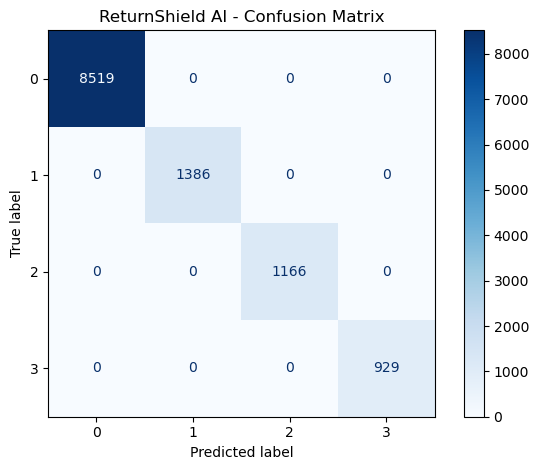

In [63]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Display the matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ReturnShield AI - Confusion Matrix")
plt.tight_layout()
plt.show()

In [64]:

import joblib
import os

# Create a folder for saved models
os.makedirs("returnshield_models", exist_ok=True)

# Save the trained Random Forest model
joblib.dump(
    rf_model,
    "returnshield_models/random_forest_model.pkl"
)

# Save the preprocessing pipeline
joblib.dump(
    preprocessor,
    "returnshield_models/preprocessor.pkl"
)

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [65]:

print(os.listdir("returnshield_models"))

['preprocessor.pkl', 'random_forest_model.pkl']


In [66]:

import pandas as pd
import joblib

# Load the saved model and preprocessor
rf_model = joblib.load(
    "returnshield_models/random_forest_model.pkl"
)

preprocessor = joblib.load(
    "returnshield_models/preprocessor.pkl"
)

def predict_return_abuse(order_details):
    # Convert input details into a DataFrame
    input_df = pd.DataFrame([order_details])

    # Remove ID columns if they are present
    input_df = input_df.drop(
        columns=["order_id", "customer_id"],
        errors="ignore"
    )

    # Convert date columns and extract date components
    for col in ["order_date", "return_date"]:
        if col in input_df.columns:
            input_df[col] = pd.to_datetime(
                input_df[col], errors="coerce"
            )
            input_df[col + "_year"] = input_df[col].dt.year
            input_df[col + "_month"] = input_df[col].dt.month
            input_df[col + "_day"] = input_df[col].dt.day
            input_df = input_df.drop(columns=[col])

    # Match the exact feature columns used during training
    expected_columns = preprocessor.feature_names_in_
    input_df = input_df.reindex(columns=expected_columns)

    # Preprocess and predict
    processed_input = preprocessor.transform(input_df)
    prediction = rf_model.predict(processed_input)[0]

    # Map predicted label to a readable category
    labels = {
        0: "Legitimate",
        1: "Policy Abuser",
        2: "Fraudulent Return"
    }

    return labels.get(prediction, str(prediction))

In [67]:

import pandas as pd
import joblib

# Load the saved model and preprocessor
rf_model = joblib.load(
    "returnshield_models/random_forest_model.pkl"
)

preprocessor = joblib.load(
    "returnshield_models/preprocessor.pkl"
)

def predict_return_abuse(order_details):
    # Convert input details into a DataFrame
    input_df = pd.DataFrame([order_details])

    # Remove ID columns if they are present
    input_df = input_df.drop(
        columns=["order_id", "customer_id"],
        errors="ignore"
    )

    # Convert date columns and extract date components
    for col in ["order_date", "return_date"]:
        if col in input_df.columns:
            input_df[col] = pd.to_datetime(
                input_df[col], errors="coerce"
            )
            input_df[col + "_year"] = input_df[col].dt.year
            input_df[col + "_month"] = input_df[col].dt.month
            input_df[col + "_day"] = input_df[col].dt.day
            input_df = input_df.drop(columns=[col])

    # Match the exact feature columns used during training
    expected_columns = preprocessor.feature_names_in_
    input_df = input_df.reindex(columns=expected_columns)

    # Preprocess and predict
    processed_input = preprocessor.transform(input_df)
    prediction = rf_model.predict(processed_input)[0]

    # Map predicted label to a readable category
    labels = {
        0: "Legitimate",
        1: "Policy Abuser",
        2: "Fraudulent Return"
    }

    return labels.get(prediction, str(prediction))

In [69]:

# Create one test order using the original dataset's columns
sample_order = x.iloc[0].to_dict()

# Predict the return-abuse category
prediction = predict_return_abuse(sample_order)

print("ReturnShield AI Prediction:", prediction)

ReturnShield AI Prediction: Legitimate


In [70]:
# %pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [71]:

import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.51.0


In [72]:

import os
print(os.getcwd())

C:\Users\SM\Projects_ML


In [73]:
import sklearn
import joblib

print("Notebook scikit-learn:", sklearn.__version__)
print("Notebook joblib:", joblib.__version__)

Notebook scikit-learn: 1.7.2
Notebook joblib: 1.5.2


In [75]:

# Check the target distribution
print("Target class distribution:")
print(y.value_counts().sort_index())

print("\nTarget class percentages:")
print(
    (y.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

# Check for suspicious features
suspicious_features = [
    col for col in x.columns
    if any(word in col.lower()
           for word in ["abuse", "fraud", "label", "target"])
]

print("\nPotentially suspicious features:")
print(suspicious_features)

Target class distribution:
abuse_label
0    42060
1     7192
2     6112
3     4636
Name: count, dtype: int64

Target class percentages:
abuse_label
0    70.10
1    11.99
2    10.19
3     7.73
Name: proportion, dtype: float64

Potentially suspicious features:
['abuse_type']


In [76]:

print("Abuse type mapping for each label:")

print(
    df.groupby("abuse_label")["abuse_type"]
    .unique()
)

Abuse type mapping for each label:
abuse_label
0           [Legitimate]
1        [Policy Abuser]
2    [Fraudulent Return]
3           [Wardrobing]
Name: abuse_type, dtype: object


In [77]:

from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Check the Random Forest's predictions on the held-out test set
print("Test Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

# Inspect the features actually used for training
print("\nTraining feature columns:")
print(list(x.columns))

# Check whether abuse_type was removed from X
print("\nIs abuse_type in X?", "abuse_type" in x.columns)
print("Is abuse_label in X?", "abuse_label" in x.columns)

Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8519
           1       1.00      1.00      1.00      1386
           2       1.00      1.00      1.00      1166
           3       1.00      1.00      1.00       929

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000


Training feature columns:
['order_id', 'customer_id', 'age', 'account_age_days', 'customer_segment', 'country', 'platform', 'device_type', 'payment_method', 'product_category', 'avg_order_value_usd', 'refund_amount_requested_usd', 'is_high_value_item', 'discount_used', 'order_date', 'return_date', 'days_to_return', 'return_reason', 'total_orders_lifetime', 'total_returns_lifetime', 'return_rate_pct', 'item_returned_opened', 'return_packaging_intact', 'photo_evidence_provided', 'tracking_number_valid', 'shipping_carr

In [78]:

# Remove target-related and identifier columns from the features
columns_to_drop = [
    "abuse_type",
    "abuse_label",
    "order_id",
    "customer_id"
]

X = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

y = df["abuse_label"]

print("Is abuse_type in X?", "abuse_type" in X.columns)
print("Is abuse_label in X?", "abuse_label" in X.columns)
print("Feature count:", X.shape[1])

Is abuse_type in X? False
Is abuse_label in X? False
Feature count: 31


In [79]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Split the data again using the corrected features
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 48000
Testing rows: 12000
Numeric features: 21
Categorical features: 10


In [80]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Preprocess numeric columns
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Preprocess categorical columns
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Processed training shape: (48000, 1526)
Processed testing shape: (12000, 1526)
Preprocessing completed successfully!


In [82]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Train a fresh model using the corrected features
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

# Predict on the unseen test data
y_pred_rf = rf_model.predict(X_test_processed)

# Evaluate the model
print("Random Forest Test Accuracy:",
      round(accuracy_score(y_test, y_pred_rf), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Test Accuracy: 0.9992

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      8412
           1       0.99      1.00      1.00      1439
           2       1.00      0.99      1.00      1222
           3       1.00      1.00      1.00       927

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000


Confusion Matrix:
[[8412    0    0    0]
 [   0 1438    0    1]
 [   0    6 1215    1]
 [   0    2    0  925]]


Top 15 features used by Random Forest:
                            Feature  Importance
                num__days_to_return    0.116908
               num__return_rate_pct    0.109401
     num__wishlist_to_cart_time_hrs    0.086419
        num__total_returns_lifetime    0.071951
     num__customer_support_contacts    0.058890
   num__refund_amount_requested_usd    0.056073
         num__tracking_number_valid    0.055686
           num__avg_order_value_usd    0.053938
         num__total_orders_lifetime    0.036267
        num__previous_dispute_count    0.032076
          num__item_returned_opened    0.031927
            num__is_high_value_item    0.031483
   num__refund_to_different_account    0.025582
        num__multiple_accounts_flag    0.025051
num__address_change_before_delivery    0.017450


<Axes: title={'center': 'Top 15 Features — ReturnShield AI'}, ylabel='Feature'>

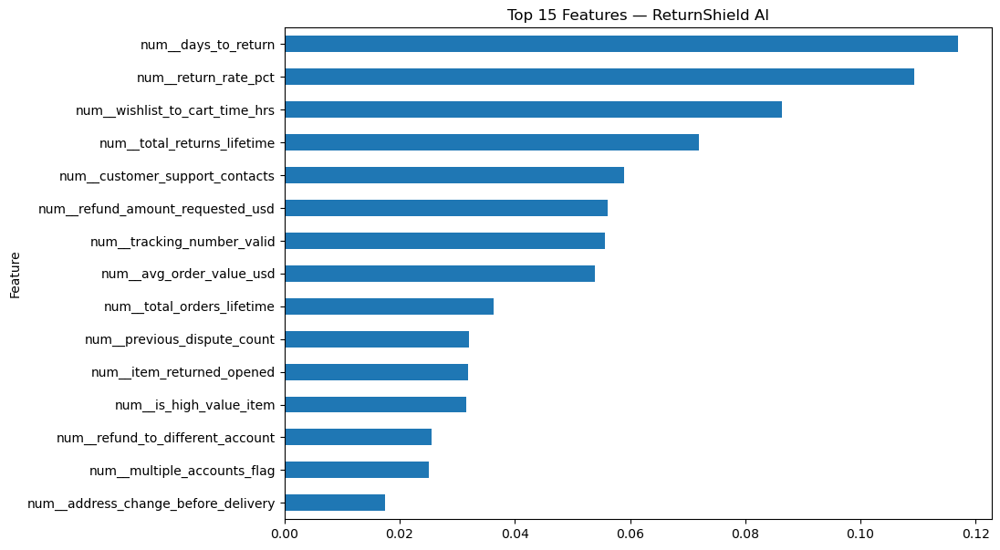

In [83]:

import pandas as pd

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 features used by Random Forest:")
print(importance_df.head(15).to_string(index=False))

# Visualize the top 15 features
importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 7),
    legend=False,
    title="Top 15 Features — ReturnShield AI"
)

In [84]:

# Check duplicate rows in the original dataset
print("Exact duplicate rows:", df.duplicated().sum())

# Check duplicate feature rows after removing identifiers and target columns
X_check = df.drop(
    columns=[
        "order_id",
        "customer_id",
        "abuse_type",
        "abuse_label"
    ],
    errors="ignore"
)

print(
    "Duplicate feature rows (excluding IDs and target):",
    X_check.duplicated().sum()
)

# Check whether the same feature patterns have different labels
check_df = X_check.copy()
check_df["abuse_label"] = df["abuse_label"].values

label_counts_per_pattern = (
    check_df.groupby(list(X_check.columns), dropna=False)["abuse_label"]
    .nunique()
)

print(
    "Repeated feature patterns with conflicting labels:",
    (label_counts_per_pattern > 1).sum()
)

Exact duplicate rows: 0
Duplicate feature rows (excluding IDs and target): 0
Repeated feature patterns with conflicting labels: 0


In [85]:

import os
import joblib

# Create the model folder if it doesn't exist
os.makedirs("returnshield_models", exist_ok=True)

# Save the newly trained model and corrected preprocessor
joblib.dump(
    rf_model,
    "returnshield_models/random_forest_model.pkl"
)

joblib.dump(
    preprocessor,
    "returnshield_models/preprocessor.pkl"
)

print("Corrected model saved successfully!")
print("Corrected preprocessor saved successfully!")
print("Model classes:", rf_model.classes_)
print("Number of training features:", X.shape[1])

Corrected model saved successfully!
Corrected preprocessor saved successfully!
Model classes: [0 1 2 3]
Number of training features: 31


In [86]:
import os
print(os.getcwd())

C:\Users\SM\Projects_ML


In [87]:

import os

print("Notebook save location:")
print(os.getcwd())

print("\nModel folder contents:")
print(os.listdir("returnshield_models"))

Notebook save location:
C:\Users\SM\Projects_ML

Model folder contents:
['preprocessor.pkl', 'random_forest_model.pkl']


In [88]:

import os

print("Notebook folder:", os.getcwd())
print(
    "Model file exists:",
    os.path.exists("returnshield_models/random_forest_model.pkl")
)
print(
    "Preprocessor file exists:",
    os.path.exists("returnshield_models/preprocessor.pkl")
)

Notebook folder: C:\Users\SM\Projects_ML
Model file exists: True
Preprocessor file exists: True
